# Robustness of the cleaning rules

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
import sys; sys.path.insert(0, "..")
from sklearn.metrics import adjusted_rand_score
from src.models.spherical_kmeans import SphericalKMeans

chars = char_names()
COLS_OVER_30 = ["realestate", "rd_sale", "rd_mve", "stdacc", "stdcf", "orgcap", "secured", "grltnoa"]
SPARSE_FLAGS = ["sin", "divi", "divo", "rd"]
TESTED = ["convind", "securedind", "ps", "ms", "nincr"]
pre_corr = [c for c in chars if c not in COLS_OVER_30 + SPARSE_FLAGS]
full = size_zerotrade_filter(chars_lazy().join(returns_lazy(), on=["permno", "ym"], how="inner")).collect()
full = full.with_columns(pl.sum_horizontal([pl.col(c).is_null() for c in chars]).alias("n_missing_all"),
                         pl.sum_horizontal([pl.col(c).is_null() for c in pre_corr]).alias("n_missing_kept"))
is_ = full.filter(pl.col("DATE") <= IS_END_DATE)
kept_is = is_.filter(pl.col("n_missing_all") <= len(chars) / 2)
kept_oos = full.filter((pl.col("DATE") > IS_END_DATE) & (pl.col("n_missing_all") <= len(chars) / 2))
h1 = pl.col("DATE") < 19980101

def avg_corr(frame, cols, ret=None):
    """Average monthly pairwise-complete correlation of rank-normalised columns, plus monthly ICs vs ret."""
    P = len(cols); S = np.zeros((P, P)); N = np.zeros((P, P)); ics = []
    for _, g in frame.group_by("DATE", maintain_order=True):
        X = g.select(cols).to_numpy(); M = ~np.isnan(X); Z = np.where(M, X, 0.0); Mf = M.astype(float)
        n = Mf.T @ Mf; sx = Z.T @ Mf; sxx = (Z ** 2).T @ Mf; sxy = Z.T @ Z
        with np.errstate(invalid="ignore", divide="ignore"):
            var = sxx / n - (sx / n) ** 2
            C = (sxy / n - (sx / n) * (sx.T / n)) / np.sqrt(var * var.T)
        ok = (n > 100) & np.isfinite(C); S += np.where(ok, C, 0); N += ok
        if ret is not None:
            r = g[ret].to_numpy()
            ics.append([np.corrcoef(X[M[:, k], k], r[M[:, k]])[0, 1] if M[:, k].sum() > 100 else np.nan for k in range(P)])
    C = S / N; np.fill_diagonal(C, 1.0)
    return C, np.array(ics)

## Row rule: counted over all characteristics vs over kept features

In [3]:
a = is_["n_missing_all"] > len(chars) / 2
b = is_["n_missing_kept"] > len(pre_corr) / 2
pl.DataFrame({"removed_all_chars": [a.mean()], "removed_kept_features": [b.mean()], "rows_disagree": [(a != b).mean()]})

removed_all_chars,removed_kept_features,rows_disagree
f64,f64,f64
0.1891,0.1855,0.0035


## Row rule: share removed by year (in-sample and out-of-sample)

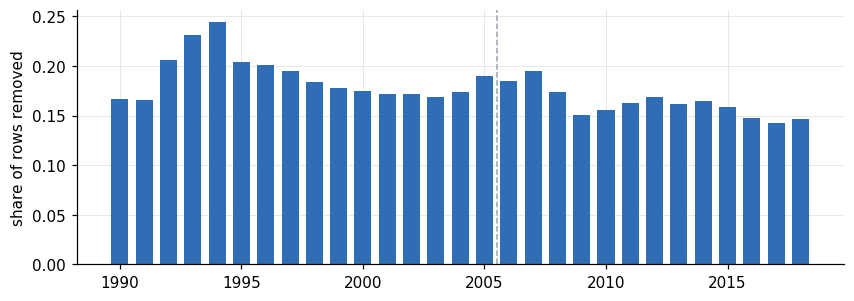

In [4]:
yr = full.group_by((pl.col("DATE") // 10000).alias("year")).agg((pl.col("n_missing_all") > len(chars) / 2).mean().alias("removed")).sort("year")
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(yr["year"], yr["removed"], color=BLUE, width=0.7); ax.axvline(2005.5, color=GREY, ls="--", lw=1)
ax.set_ylabel("share of rows removed"); plt.show()

## Column missingness after the row rule (25 most-missing): in-sample halves and out-of-sample

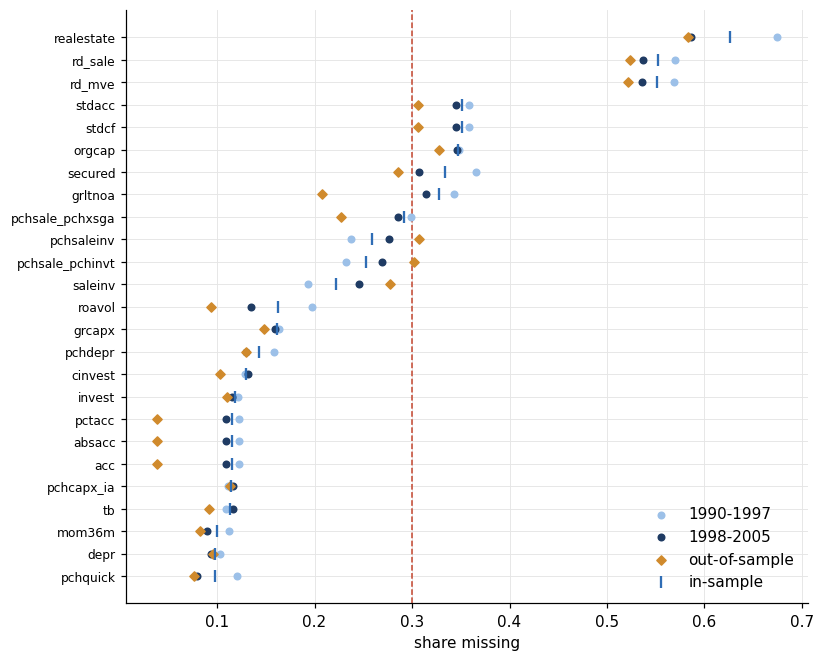

In [5]:
miss = pl.DataFrame({"char": chars,
    "in-sample": [kept_is[c].null_count() / kept_is.height for c in chars],
    "1990-1997": [kept_is.filter(h1)[c].null_count() / kept_is.filter(h1).height for c in chars],
    "1998-2005": [kept_is.filter(~h1)[c].null_count() / kept_is.filter(~h1).height for c in chars],
    "out-of-sample": [kept_oos[c].null_count() / kept_oos.height for c in chars]}).sort("in-sample", descending=True).head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(miss.height)
for col, color, m in [("1990-1997", "#9cc0e8", "o"), ("1998-2005", "#1f3b63", "o"), ("out-of-sample", "#d08a2c", "D"), ("in-sample", BLUE, "|")]:
    ax.scatter(miss[col], y, s=60 if m == "|" else 18, color=color, marker=m, label=col, zorder=3)
ax.axvline(0.3, color="#c4462f", lw=1, ls="--")
ax.set_yticks(y, miss["char"], fontsize=8); ax.set_xlabel("share missing"); ax.legend(frameon=False, loc="lower right"); plt.show()

## Largest |correlation| among remaining features after the row rule

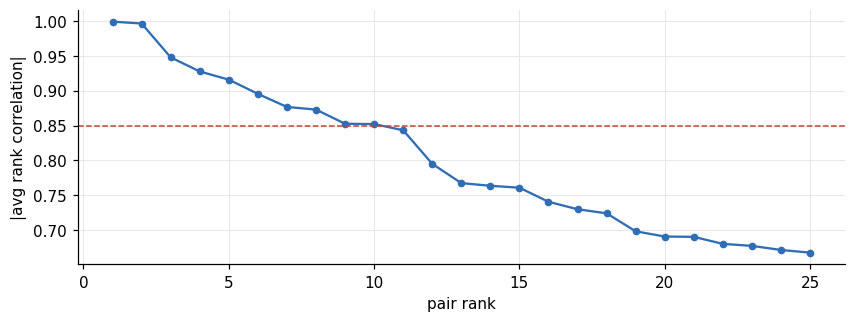

In [6]:
d = rank_normalise(kept_is, pre_corr + ["ret"])
C, ics = avg_corr(d, pre_corr, ret="ret")
C1, ics1 = avg_corr(d.filter(h1), pre_corr, ret="ret")
C2, ics2 = avg_corr(d.filter(~h1), pre_corr, ret="ret")
iu = np.triu_indices(len(pre_corr), 1)
top = np.sort(np.abs(C[iu]))[::-1][:25]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(range(1, 26), top, marker="o", ms=4, color=BLUE, lw=1.5)
ax.axhline(0.85, color="#c4462f", lw=1, ls="--")
ax.set_xlabel("pair rank"); ax.set_ylabel("|avg rank correlation|"); plt.show()

## Pairs with |correlation| > 0.8: stability across halves and IC t-stat by half

In [7]:
def t_of(x):
    return np.nanmean(x, 0) / (np.nanstd(x, 0, ddof=1) / np.sqrt((~np.isnan(x)).sum(0)))
T, T1, T2 = t_of(ics), t_of(ics1), t_of(ics2)
pl.DataFrame([{"a": pre_corr[i], "b": pre_corr[j], "rho": C[i, j], "rho_1990_1997": C1[i, j], "rho_1998_2005": C2[i, j],
               "ic_t_a": T[i], "ic_t_b": T[j], "ic_t_a_1990_1997": T1[i], "ic_t_b_1990_1997": T1[j],
               "ic_t_a_1998_2005": T2[i], "ic_t_b_1998_2005": T2[j]}
              for i, j in zip(*iu) if abs(C[i, j]) > 0.8]).sort(pl.col("rho").abs(), descending=True)

a,b,rho,rho_1990_1997,rho_1998_2005,ic_t_a,ic_t_b,ic_t_a_1990_1997,ic_t_b_1990_1997,ic_t_a_1998_2005,ic_t_b_1998_2005
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""beta""","""betasq""",0.9986,0.9991,0.9982,-0.9972,-1.0090,-0.0380,-0.0560,-1.2274,-1.2287
"""pchsale_pchinvt""","""pchsaleinv""",0.9960,0.9962,0.9957,2.7971,3.1058,1.5578,1.7057,2.4285,2.7167
"""dolvol""","""ill""",-0.9475,-0.9391,-0.9558,1.1142,-2.3157,1.9011,-2.8047,-0.3056,-0.4500
"""pchcurrat""","""pchquick""",0.9273,0.9185,0.9361,-1.9928,-1.2946,-1.9830,-1.4874,-0.8286,-0.3533
"""turn""","""zerotrade""",-0.9156,-0.8924,-0.9386,0.1916,-1.3360,0.6485,-1.6608,-0.3115,-0.3306
"""mvel1""","""ill""",-0.8953,-0.8914,-0.8992,1.3916,-2.3157,2.0265,-2.8047,-0.0781,-0.4500
"""baspread""","""retvol""",0.8766,0.8765,0.8767,-1.5865,-2.2518,-1.6433,-2.3864,-0.7881,-1.0716
"""maxret""","""retvol""",0.8728,0.8788,0.8669,-3.1569,-2.2518,-2.7484,-2.3864,-1.9075,-1.0716
"""currat""","""quick""",0.8526,0.8453,0.8598,-1.7115,-1.2709,-0.9275,-0.2817,-1.4767,-1.3935


## IC t-stat of the binary flags and scores (in-sample, after the row rule)

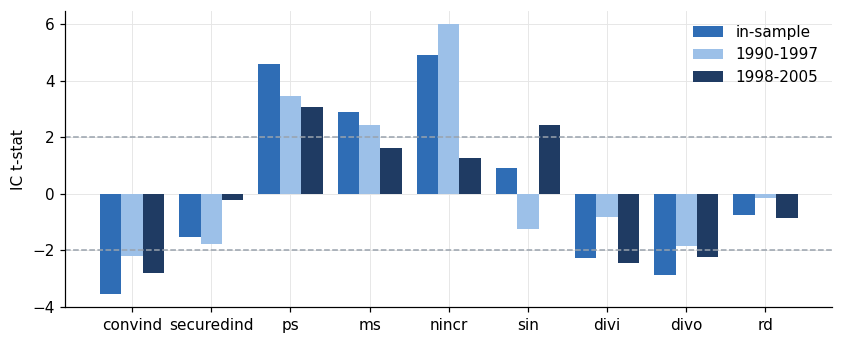

In [8]:
ix = {c: i for i, c in enumerate(pre_corr)}
ds = rank_normalise(kept_is, SPARSE_FLAGS + ["ret"])
_, ics_f = avg_corr(ds, SPARSE_FLAGS, ret="ret")
_, ics_f1 = avg_corr(ds.filter(h1), SPARSE_FLAGS, ret="ret")
_, ics_f2 = avg_corr(ds.filter(~h1), SPARSE_FLAGS, ret="ret")
names = TESTED + SPARSE_FLAGS
vals = {"in-sample": list(T[[ix[c] for c in TESTED]]) + list(t_of(ics_f)),
        "1990-1997": list(T1[[ix[c] for c in TESTED]]) + list(t_of(ics_f1)),
        "1998-2005": list(T2[[ix[c] for c in TESTED]]) + list(t_of(ics_f2))}
fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(names)); w = 0.27
for k, (lab, color) in enumerate([("in-sample", BLUE), ("1990-1997", "#9cc0e8"), ("1998-2005", "#1f3b63")]):
    ax.bar(x + (k - 1) * w, vals[lab], w, color=color, label=lab)
for v in (-2, 2):
    ax.axhline(v, color=GREY, lw=1, ls="--")
ax.set_xticks(x, names); ax.set_ylabel("IC t-stat"); ax.legend(frameon=False); plt.show()

## Max |correlation| of each tested column with the other remaining features

In [9]:
pl.DataFrame({"char": TESTED, "max_abs_rho": [max(abs(C[ix[c], ix[k]]) for k in pre_corr if k != c) for c in TESTED],
              "most_correlated_with": [max((k for k in pre_corr if k != c), key=lambda k: abs(C[ix[c], ix[k]])) for c in TESTED]})

char,max_abs_rho,most_correlated_with
str,f64,str
"""convind""",0.1460,"""turn"""
"""securedind""",0.1951,"""idiovol"""
"""ps""",0.3782,"""pchgm_pchsale"""
"""ms""",0.5056,"""cashdebt"""
"""nincr""",0.3613,"""roeq"""


## Spherical k-means (K=30) with and without convind, securedind: 12 in-sample months

In [10]:
CORR_DROPS = ["betasq", "pchsale_pchinvt", "dolvol", "pchquick", "mvel1", "turn", "retvol", "quick"]
FLAGS = ["convind", "securedind"]
base = [c for c in pre_corr if c not in CORR_DROPS + FLAGS]
months = kept_is["DATE"].unique().sort().to_list()[::16]
km = (rank_normalise(kept_is.filter(pl.col("DATE").is_in(months)), base + FLAGS)
        .with_columns([pl.col(c).fill_null(0.0) for c in base + FLAGS]))
pl.DataFrame({"feature": FLAGS + ["continuous features (avg)"],
              "mean_squared_value": [float((km[f].to_numpy() ** 2).mean()) for f in FLAGS] + [float((km.select(base).to_numpy() ** 2).mean())]})

feature,mean_squared_value
str,f64
"""convind""",0.1235
"""securedind""",0.2483
"""continuous features (avg)""",0.3129


In [11]:
def labels(X, seed):
    m = SphericalKMeans(30, random_state=seed).fit(X)
    return m.transform(X).argmax(1)
def pure_share(flag, lab):
    sizes = np.array([np.sum(lab == k) for k in np.unique(lab)])
    major = np.array([max(flag[lab == k].mean(), 1 - flag[lab == k].mean()) for k in np.unique(lab)])
    return sizes[major > 0.95].sum() / len(lab)
rows = []
for dt in months:
    g = km.filter(pl.col("DATE") == dt)
    Xb, Xf = g.select(base).to_numpy(), g.select(base + FLAGS).to_numpy()
    a, b, c = labels(Xb, 1), labels(Xb, 2), labels(Xf, 1)
    row = {"ari_seed1_vs_seed2_without": adjusted_rand_score(a, b), "ari_without_vs_with_flags": adjusted_rand_score(a, c)}
    for f in FLAGS:
        v = g[f].to_numpy() > 0
        row[f"{f}_in_95pct_pure_clusters_without"] = pure_share(v, a)
        row[f"{f}_in_95pct_pure_clusters_with"] = pure_share(v, c)
    rows.append(row)
pl.DataFrame(rows).mean().transpose(include_header=True, header_name="metric", column_names=["mean over months"])

metric,mean over months
str,f64
"""ari_seed1_vs_seed2_without""",0.4406
"""ari_without_vs_with_flags""",0.4251
"""convind_in_95pct_pure_clusters…",0.1406
"""convind_in_95pct_pure_clusters…",0.1750
"""securedind_in_95pct_pure_clust…",0.0509
"""securedind_in_95pct_pure_clust…",0.0592
